# Aula 7 — Algoritmos de regressão para previsão de variáveis industriais  
## Versão do aluno

**Objetivo da atividade**  
Construir e comparar modelos de regressão para prever a variável `vazao_real_l_min`, registrando as etapas do experimento e interpretando os resultados.

**Arquivo utilizado**  
`dados_aula7_regressao_industrial.csv`

## 1. Importação das bibliotecas

Preencha a célula abaixo com as bibliotecas necessárias para:
- manipulação dos dados;
- separação treino/validação;
- pré-processamento;
- criação dos modelos;
- cálculo das métricas.

In [ ]:
# Escreva suas importações aqui
import pandas as pd
import numpy as np
# Separação treino/validação
from sklearn.model_selection import train_test_split
# Pré-processamento
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
# Modelo
from sklearn.linear_model import LinearRegression
# Métricas
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# Visualização
import matplotlib.pyplot as plt

## 2. Carregamento da base

Carregue o arquivo CSV e mostre:
- dimensão da base;
- cinco primeiras linhas;
- nomes das colunas.

In [ ]:
# Carregue a base de dados nesta célula
df = pd.read_csv("dados_aula7_regressao_industrial.csv")

# Analise valores faltantes e tipos de dados
print("Dimensão da base:", df.shape)

# Visualizar as 5 primeiras linhas
display(df.head())

# Listar os nomes das colunas
print("\nColunas:")
print(df.columns.tolist())

Dimensão da base: (266, 15)


,linha_producao,turno,produto_quimico,tipo_valvula,pressao_linha_bar,temperatura_produto_c,abertura_valvula_pct,vibracao_bomba_mm_s,ph_produto,consumo_energia_kwh,horas_operacao_bomba,particulas_ppm,viscosidade_cP,falha_operacional,vazao_real_l_min
0,Linha_B,Noite,Reagente_Y,Borboleta,7.20,29.54,41.56,3.90,6.71,122.07,1561,21.36,55.49,0,27.52
1,Linha_C,Tarde,Solvente_X,Borboleta,5.30,50.43,52.92,2.21,5.82,128.13,1501,19.75,48.70,0,36.80
2,Linha_B,Noite,Solvente_X,Globo,3.95,55.37,73.58,1.94,6.03,134.24,1188,21.45,15.00,0,45.95
3,Linha_B,Tarde,Aditivo_Z,Esfera,4.81,40.37,71.75,3.38,6.71,120.44,2095,13.30,48.18,0,49.50
4,Linha_A,Noite,Solvente_X,Borboleta,5.95,40.51,NaN,NaN,6.59,128.15,2003,11.58,55.20,0,46.66



Colunas:
['linha_producao', 'turno', 'produto_quimico', 'tipo_valvula', 'pressao_linha_bar', 'temperatura_produto_c', 'abertura_valvula_pct', 'vibracao_bomba_mm_s', 'ph_produto', 'consumo_energia_kwh', 'horas_operacao_bomba', 'particulas_ppm', 'viscosidade_cP', 'falha_operacional', 'vazao_real_l_min']


## 3. Inspeção inicial da base

Verifique:
- valores faltantes por coluna;
- tipos de dados;
- qual coluna será usada como variável-alvo.

**Pergunta para registro:**  
Por que este problema é classificado como regressão?
  - Porque a variável que queremos prever representa uma grandeza numérica contínua, e não uma classe ou rótulo discreto.

In [ ]:
# Verificar valores faltantes por coluna
print("Valores faltantes por coluna:")
display(df.isna().sum().sort_values(ascending=False))

# Verificar os tipos de dados
print("\nTipos de dados:")
display(df.dtypes)

Valores faltantes por coluna:


,0
abertura_valvula_pct,7
vibracao_bomba_mm_s,7
pressao_linha_bar,6
temperatura_produto_c,6
produto_quimico,5
turno,0
linha_producao,0
tipo_valvula,0
ph_produto,0
consumo_energia_kwh,0



Tipos de dados:


,0
linha_producao,object
turno,object
produto_quimico,object
tipo_valvula,object
pressao_linha_bar,float64
temperatura_produto_c,float64
abertura_valvula_pct,float64
vibracao_bomba_mm_s,float64
ph_produto,float64
consumo_energia_kwh,float64


## 4. Definição de X e y

Separe:
- `X`: variáveis preditoras;
- `y`: variável-alvo `vazao_real_l_min`.

Depois, mostre a dimensão de cada um.

In [ ]:
# Separe X e y
# X = todas as colunas exceto a variável-alvo
X = df.drop(columns=["vazao_real_l_min"])

# y = apenas a variável-alvo
y = df["vazao_real_l_min"]

# Verificar dimensões
print("Dimensão de X:", X.shape)
print("Dimensão de y:", y.shape)

# Visualizar primeiras linhas
display(X.head())
display(y.head())

Dimensão de X: (266, 14)
Dimensão de y: (266,)


,linha_producao,turno,produto_quimico,tipo_valvula,pressao_linha_bar,temperatura_produto_c,abertura_valvula_pct,vibracao_bomba_mm_s,ph_produto,consumo_energia_kwh,horas_operacao_bomba,particulas_ppm,viscosidade_cP,falha_operacional
0,Linha_B,Noite,Reagente_Y,Borboleta,7.20,29.54,41.56,3.90,6.71,122.07,1561,21.36,55.49,0
1,Linha_C,Tarde,Solvente_X,Borboleta,5.30,50.43,52.92,2.21,5.82,128.13,1501,19.75,48.70,0
2,Linha_B,Noite,Solvente_X,Globo,3.95,55.37,73.58,1.94,6.03,134.24,1188,21.45,15.00,0
3,Linha_B,Tarde,Aditivo_Z,Esfera,4.81,40.37,71.75,3.38,6.71,120.44,2095,13.30,48.18,0
4,Linha_A,Noite,Solvente_X,Borboleta,5.95,40.51,NaN,NaN,6.59,128.15,2003,11.58,55.20,0


,vazao_real_l_min
0,27.52
1,36.80
2,45.95
3,49.50
4,46.66


## 5. Identificação das colunas numéricas e categóricas

Liste:
- colunas numéricas;
- colunas categóricas.

In [ ]:
# Identifique as colunas numéricas e categóricas
# Selecionar colunas numéricas
colunas_numericas = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Selecionar colunas categóricas
colunas_categoricas = X.select_dtypes(include=["object"]).columns.tolist()

print("Colunas numéricas:")
print(colunas_numericas)
print("\nColunas categóricas:")
print(colunas_categoricas)

Colunas numéricas:
['pressao_linha_bar', 'temperatura_produto_c', 'abertura_valvula_pct', 'vibracao_bomba_mm_s', 'ph_produto', 'consumo_energia_kwh', 'horas_operacao_bomba', 'particulas_ppm', 'viscosidade_cP', 'falha_operacional']

Colunas categóricas:
['linha_producao', 'turno', 'produto_quimico', 'tipo_valvula']


## 6. Construção do pré-processamento

Monte um pipeline com:

### Para colunas numéricas
- preenchimento de faltantes com mediana;
- padronização.

### Para colunas categóricas
- preenchimento com valor mais frequente;
- codificação com `OneHotEncoder`.

Depois, una tudo em um `ColumnTransformer`.

In [ ]:
# Monte o preprocessador aqui
# Pipeline para dados numéricos
transformador_numerico = Pipeline(steps=[
  ("imputer", SimpleImputer(strategy="median")),
  ("scaler", StandardScaler())
])

# Pipeline para dados categóricos
transformador_categorico = Pipeline(steps=[
  ("imputer", SimpleImputer(strategy="most_frequent")),
  ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
# Combinando tudo com ColumnTransformer
preprocessador = ColumnTransformer(transformers=[
  ("num", transformador_numerico, colunas_numericas),
  ("cat", transformador_categorico, colunas_categoricas)
])
# Verificar estrutura
preprocessador

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['pressao_linha_bar', 'temperatura_produto_c',
                                  'abertura_valvula_pct', 'vibracao_bomba_mm_s',
                                  'ph_produto', 'consumo_energia_kwh',
                                  'horas_operacao_bomba', 'particulas_ppm',
                                  'viscosidade_cP', 'falha_operacional']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['linha_producao', 'turno', 'produto_quimico',
                                  'tipo_valvula'])])

## 7. Separação dos dados em treino e validação

Realize a separação dos dados usando:
- `test_size=0.2`
- `random_state=42`

Mostre as dimensões de:
- `X_treino`
- `X_validacao`
- `y_treino`
- `y_validacao`

**Registro técnico:**  
Explique, com suas palavras, por que não devemos treinar e avaliar no mesmo conjunto de dados.
  - Não devemos treinar e avaliar um modelo no mesmo conjunto de dados porque isso gera uma falsa sensação de desempenho e mascara o overfitting.

In [ ]:
# Faça a separação treino/validação
X_treino, X_validacao, y_treino, y_validacao = train_test_split(
  X, y,
  test_size=0.2, # 20% para validação
  random_state=42 # Garante reprodutibilidade
)

print("X_treino:", X_treino.shape)
print("X_validacao:", X_validacao.shape)
print("y_treino:", y_treino.shape)
print("y_validacao:", y_validacao.shape)

X_treino: (212, 14)
X_validacao: (54, 14)
y_treino: (212,)
y_validacao: (54,)


## 8. Criação do modelo de regressão linear

Monte um pipeline contendo:
- pré-processamento;
- `LinearRegression`.

In [ ]:
# Crie o modelo linear
modelo_linear = Pipeline(steps=[
  ("preprocessamento", preprocessador),
  ("modelo", LinearRegression())
])

# Verificar estrutura do pipeline
modelo_linear

Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['pressao_linha_bar',
                                                   'temperatura_produto_c',
                                                   'abertura_valvula_pct',
                                                   'vibracao_bomba_mm_s',
                                                   'ph_produto',
                                                   'consumo_energia_kwh',
                                                   'horas_operacao_bomba',
                                                   'particulas_ppm',
                                                   'viscosidade_cP',
                                                   'falha_operacional']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['linha_producao', 'turno',
                                                   'produto_quimico',
                                                   'tipo_valvula'])])),
                ('modelo', LinearRegression())])

## 9. Treinamento do modelo linear

Treine o modelo usando os dados de treino.

In [ ]:
# Treine o modelo linear
modelo_linear.fit(X_treino, y_treino)
print("Modelo linear treinado com sucesso.")

Modelo linear treinado com sucesso.


## 10. Predição com o modelo linear

Use os dados de validação para gerar previsões e mostre as primeiras comparações entre:
- valor real;
- valor previsto.

In [ ]:
# Gere predições com o modelo linear
pred_linear = modelo_linear.predict(X_validacao)

# Comparar valores reais vs. previstos
resultado_linear = pd.DataFrame({
  "valor_real": y_validacao.values,
  "predicao_linear": pred_linear
})

display(resultado_linear.head(10))

,valor_real,predicao_linear
0,34.19,31.613671
1,34.49,34.909643
2,25.94,17.411885
3,47.04,43.961261
4,38.92,41.792494
5,36.41,39.429888
6,36.49,40.983627
7,38.42,42.165993
8,40.51,44.683560
9,24.74,22.284348


## 11. Métricas do modelo linear

Calcule:
- MAE
- RMSE
- R²

Depois, registre uma interpretação breve:
- o erro ficou alto ou baixo?
  - O valor do MAE ficou médio baixo, já o RMSE está mais alto que o aceitável.
- o R² indica bom ajuste?
  - Sim, o modelo está com a precisão de 0.7368.

In [ ]:
# Calcule as métricas do modelo linear
mae_linear = mean_absolute_error(y_validacao, pred_linear)
rmse_linear = mean_squared_error(y_validacao, pred_linear)
r2_linear = r2_score(y_validacao, pred_linear)

print("Métricas - Regressão Linear")
print(f"MAE : {mae_linear:.4f}")
print(f"RMSE: {rmse_linear:.4f}")
print(f"R2 : {r2_linear:.4f}")

Métricas - Regressão Linear
MAE : 2.9592
RMSE: 14.5833
R2 : 0.7368


## 12. Criação do modelo polinomial

Monte um segundo pipeline com:
- imputação;
- padronização;
- `PolynomialFeatures(degree=2)`;
- `LinearRegression`.

Use codificação categórica para as colunas de texto.

In [ ]:
# Crie o modelo polinomial
# Pipeline numérico com features polinomiais
transformador_numerico_polinomial = Pipeline(steps=[
  ("imputer", SimpleImputer(strategy="median")),
  ("scaler", StandardScaler()),
  ("poly", PolynomialFeatures(degree=2, include_bias=False))
])

# Preprocessador polinomial
preprocessador_polinomial = ColumnTransformer(transformers=[
  ("num", transformador_numerico_polinomial, colunas_numericas),
  ("cat", transformador_categorico, colunas_categoricas)
])
# Pipeline completo com regressão linear
modelo_polinomial = Pipeline(steps=[
  ("preprocessamento", preprocessador_polinomial),
  ("modelo", LinearRegression())
])

# Verificar estrutura
modelo_polinomial

Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler()),
                                                                  ('poly',
                                                                   PolynomialFeatures(include_bias=False))]),
                                                  ['pressao_linha_bar',
                                                   'temperatura_produto_c',
                                                   'abertura_valvula_pct',
                                                   'vibracao_bomba_mm_s',
                                                   'ph_produto',
                                                   'consumo_energia_kwh',
                                                   'horas_operacao_bomba',
                                                   'particulas_ppm',
                                                   'viscosidade_cP',
                                                   'falha_operacional']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['linha_producao', 'turno',
                                                   'produto_quimico',
                                                   'tipo_valvula'])])),
                ('modelo', LinearRegression())])

## 13. Treinamento do modelo polinomial

Treine o segundo modelo com os dados de treino.

In [ ]:
# Treine o modelo polinomial
modelo_polinomial.fit(X_treino, y_treino)
print("Modelo polinomial treinado com sucesso.")

Modelo polinomial treinado com sucesso.


## 14. Predição com o modelo polinomial

Gere as predições usando os dados de validação.

In [ ]:
# Gere as predições do modelo polinomial
pred_polinomial = modelo_polinomial.predict(X_validacao)

resultado_polinomial = pd.DataFrame({
  "valor_real": y_validacao.values,
  "predicao_polinomial": pred_polinomial
})

display(resultado_polinomial.head(10))

,valor_real,predicao_polinomial
0,34.19,31.895331
1,34.49,33.277253
2,25.94,18.792153
3,47.04,42.105483
4,38.92,37.425947
5,36.41,39.812929
6,36.49,41.550155
7,38.42,39.473158
8,40.51,44.689113
9,24.74,19.616535


## 15. Métricas do modelo polinomial

Calcule:
- MAE
- RMSE
- R²

In [ ]:
# Calcule as métricas do modelo polinomial
mae_polinomial = mean_absolute_error(y_validacao, pred_polinomial)
rmse_polinomial = mean_squared_error(y_validacao, pred_polinomial)
r2_polinomial = r2_score(y_validacao, pred_polinomial)

print("Métricas - Regressão Polinomial")
print(f"MAE : {mae_polinomial:.4f}")
print(f"RMSE: {rmse_polinomial:.4f}")
print(f"R2 : {r2_polinomial:.4f}")

Métricas - Regressão Polinomial
MAE : 3.5661
RMSE: 17.5004
R2 : 0.6841


## 16. Comparação entre modelos

Monte uma tabela com as métricas dos dois modelos e responda:

1. Qual modelo teve menor erro?
  - O modelo com menor erro foi a Regressão Linear
2. Qual modelo apresentou melhor capacidade explicativa?
  - O modelo com melhor capacidade explicativa também foi a Regressão Linear.
3. Qual modelo você recomendaria para este problema?
  - Regressão Linear, superou a Regressão Polinomial em todos os critérios, apresentando erros menores e maior poder preditivo.

In [ ]:
# Monte a tabela comparativa
comparacao = pd.DataFrame({
  "Modelo": ["Regressão Linear", "Regressão Polinomial"],
  "MAE": [mae_linear, mae_polinomial],
  "RMSE": [rmse_linear, rmse_polinomial],
  "R2": [r2_linear, r2_polinomial]
})

display(comparacao.sort_values(by="RMSE"))

,Modelo,MAE,RMSE,R2
0,Regressão Linear,2.959205,14.583273,0.736763
1,Regressão Polinomial,3.566114,17.500414,0.684107


## 17. Visualização dos resultados

Crie um gráfico comparando:
- valores reais;
- predição linear;
- predição polinomial.

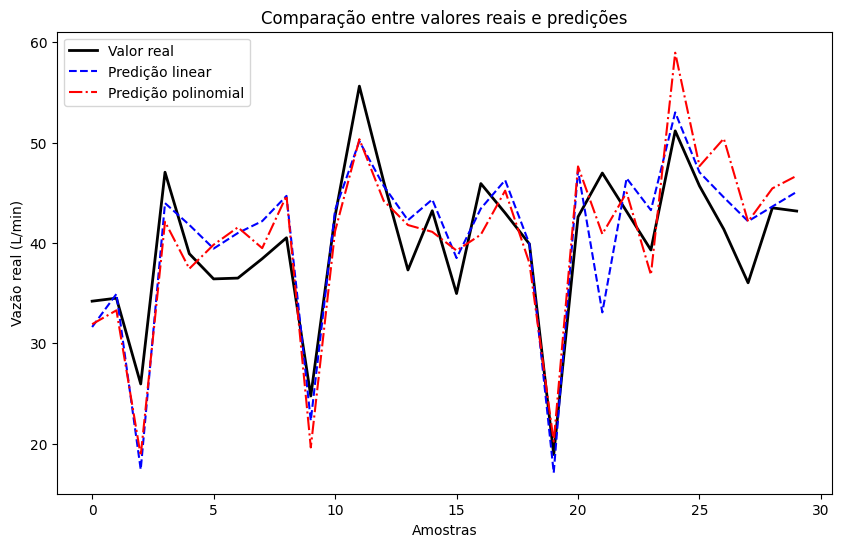

In [ ]:
# Crie um gráfico comparativo
plt.figure(figsize=(10, 6))

# Plotar os 30 primeiros pontos para melhor visualização
plt.plot(y_validacao.values[:30], label="Valor real", color="black", linewidth=2)
plt.plot(pred_linear[:30], label="Predição linear", color="blue",
linewidth=1.5, linestyle="--")
plt.plot(pred_polinomial[:30], label="Predição polinomial", color="red",
linewidth=1.5, linestyle="-.")

plt.title("Comparação entre valores reais e predições")
plt.xlabel("Amostras")
plt.ylabel("Vazão real (L/min)")
plt.legend()
plt.show()

## 18. Reflexão final

Responda no notebook:

- Qual a função da etapa de treino?
  - O algoritmo aprende os padrões dos dados e ajusta seus parâmetros internos.
- Qual a função da etapa de validação?
  - Avalia a capacidade do modelo de generalizar para dados inéditos, evitando o overfitting.
- Por que as métricas são importantes?
  - Fornecem valores objetivos para medir a qualidade, comparar modelos e orientar melhorias.
- Em que situação a regressão logística seria mais apropriada do que a regressão linear?
  - A linear prevê valores numéricos contínuos, enquanto a logística resolve problemas de classificação (categorias).

In [ ]:
# Escreva suas respostas aqui